In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df=pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
df.shape

(8807, 12)

In [4]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [5]:
print("\nDataset Description:")
df.info()


Dataset Description:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [6]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [7]:
print("\n Statistical Summary:")
df.describe()


 Statistical Summary:


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


Analyze missing values and duplicates

In [8]:
missing_summary=pd.DataFrame({
    "Column":df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage":(
        df.isnull().mean().values*100).round(2)
})

print("Duplicate rows:",df.duplicated().sum())
print("Unique show IDs:",df["show_id"].nunique())
display(df["type"].value_counts())

Duplicate rows: 0
Unique show IDs: 8807


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Clean the dataset

In [9]:
# Create a copy of the dataset
clean_df=df.copy()

# Remove duplicate rows
clean_df=clean_df.drop_duplicates()

# Fill missing values
for col in["director","cast","country","rating"]:
    clean_df[col]=clean_df[col].fillna("UnKnown")

# Convert date column
clean_df["date_added"]=pd.to_datetime(
    clean_df["date_added"],errors="coerce"
)

# Extract year added
clean_df["year_added"]=clean_df["date_added"].dt.year

# Extract numeric duration
clean_df["duration_value"]=pd.to_numeric(
    clean_df["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Display results
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))

print("\nMissing values:")
display(clean_df.isnull().sum())

Original rows: 8807
Cleaned rows: 8807

Missing values:


show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        98
release_year       0
rating             0
duration           3
listed_in          0
description        0
year_added        98
duration_value     3
dtype: int64

In [10]:
#Saving the cleaned dataset
clean_df.to_csv("Outputs/netflix_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


VISUALIZATIONS

1.Movies vs TV Shows


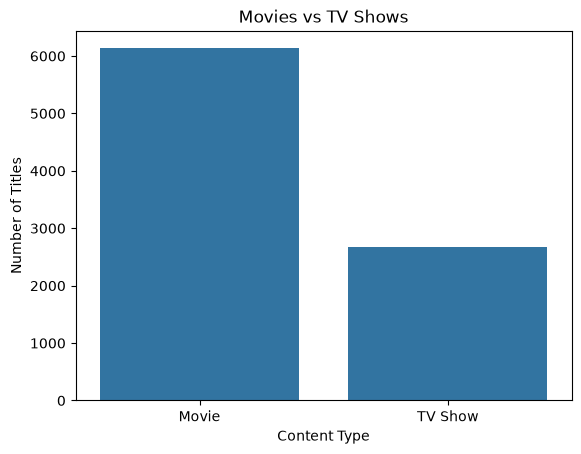

In [11]:
counts=clean_df["type"].value_counts()
sns.barplot(x=counts.index,y=counts.values)
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

2.Content by release year

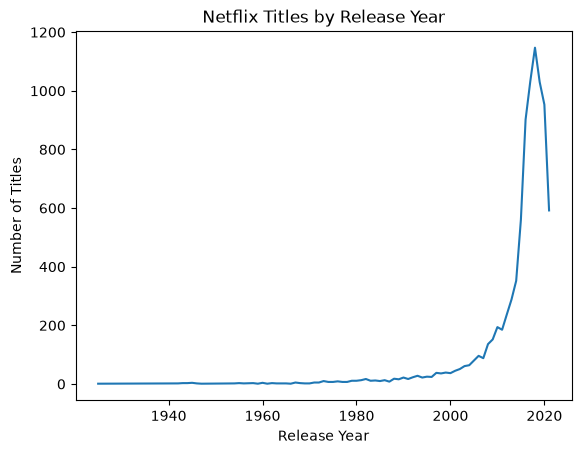

In [12]:
year_counts = clean_df["release_year"].value_counts().sort_index()

plt.plot(year_counts.index, year_counts.values)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

3.Top 10 genres

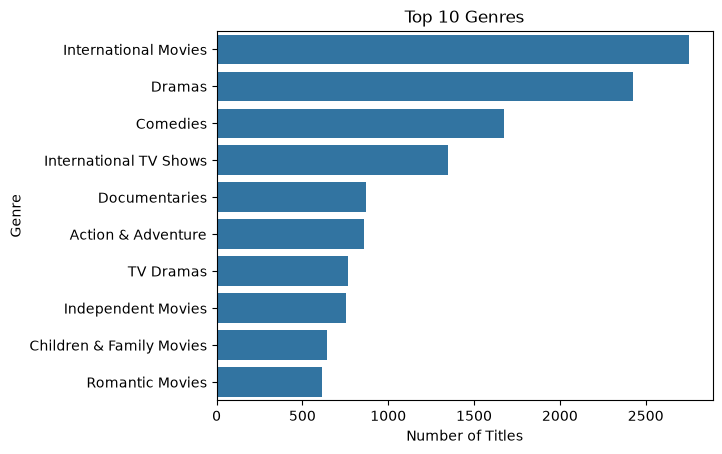

In [13]:
genre_counts = (
    clean_df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)
sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Top 10 Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()

4.Top 10 Countries

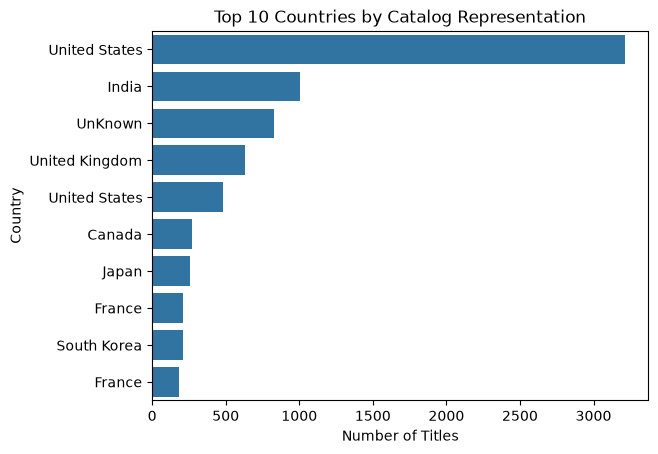

In [14]:
country_counts = (
    clean_df.loc[clean_df["country"]!="Unknown","country"]
    .str.split(",")
    .explode()
    .value_counts()
    .head(10)
)
sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries by Catalog Representation")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

5.Content ratings

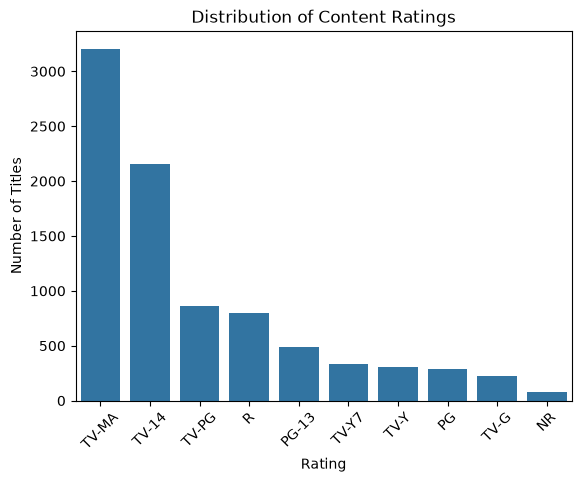

In [15]:
rating_counts = (
    clean_df.loc[clean_df["rating"]!="Unknown","rating"].value_counts().head(10)
)
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title("Distribution of Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

6.Movie Duration

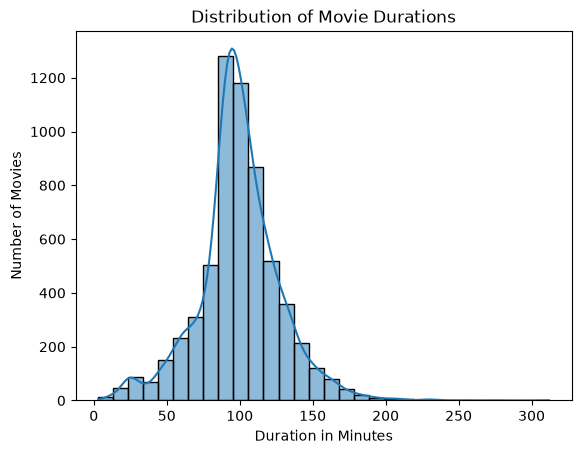

In [16]:
movies = clean_df[clean_df["type"]=="Movie"].copy()

movie_minutes = pd.to_numeric(
    movies["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)
sns.histplot(movie_minutes.dropna(), bins=30, kde=True)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration in Minutes")
plt.ylabel("Number of Movies")

plt.show()